In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_csv("daily-min-temperatures.csv")

In [3]:
data

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8
...,...,...
3645,1990-12-27,14.0
3646,1990-12-28,13.6
3647,1990-12-29,13.5
3648,1990-12-30,15.7


In [4]:
data.head()

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [6]:
data.shape

(3650, 2)

In [7]:
data.describe()

,Temp
count,3650.000000
mean,11.177753
std,4.071837
min,0.000000
25%,8.300000
50%,11.000000
75%,14.000000
max,26.300000


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
data.isna().sum()

Date    0
Temp    0
dtype: int64

In [11]:
data["Temp"].value_counts()

Temp
10.0    51
11.0    51
13.0    48
12.5    44
10.5    44
        ..
0.2      1
24.0     1
25.2     1
22.7     1
21.6     1
Name: count, Length: 229, dtype: int64

# VISUALISATION DE LA TENDACE

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='Date', ylabel='Temp'>

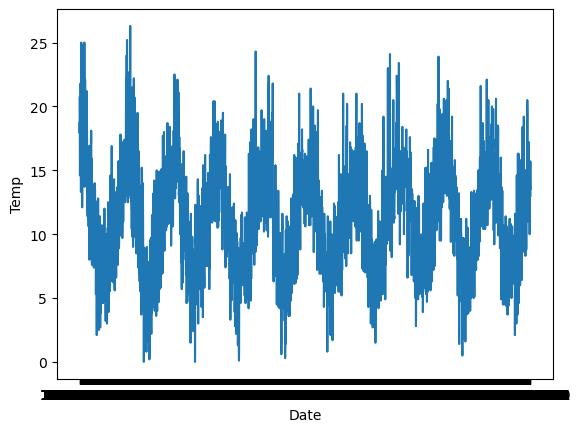

In [18]:
fig,axes = plt.subplots()

sns.lineplot(data,x="Date",y="Temp")

In [21]:
df = data[["Temp"]].values
df

array([[20.7],
       [17.9],
       [18.8],
       ...,
       [13.5],
       [15.7],
       [13. ]])

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# SEPARATION EN TRAIN ET TEST

In [27]:
train_df, test_df = train_test_split(df,test_size=0.2,random_state=42,shuffle=False)

# STANDARDISATION DE DONNEES

In [29]:
pipeline = make_pipeline(StandardScaler()
                        )


In [33]:
train_scaled = pipeline.fit_transform(train_df)
test_scaled = pipeline.transform(test_df)

# FENETRAGE DES DONNEES

In [46]:
def create_window(data,len_seq=3):
    X,y= [],[]
    for i in range(len(data) - len_seq):
        X.append(data[i:i+len_seq])
        y.append(data[i+len_seq])
     return np.array(X),np.array(y)

In [47]:
X_train, y_train = create_window(train_scaled, len_seq=30)
X_test, y_test   = create_window(test_scaled, len_seq=30)

# CREATION DE TENSORS ET DATASET

In [48]:
import torch

In [57]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

In [64]:
from torch.utils.data import TensorDataset,DataLoader

In [80]:
# creation des tensors datasets
train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

# creation des data loaders

train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader  = DataLoader(test_dataset,batch_size=32,shuffle=False)

# creation du module LSTM

In [81]:
import torch.nn as nn

In [82]:
class TempLSTM(nn.Module):
    def __init__(self,input_size=1,hidden_size=1,num_layers=1,output_size=1):
        super(TempLSTM,self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True)
        self.fc = nn.Linear(hidden_size,output_size)

    def forward(self,x):
        out,(hn,cn) = self.lstm(x)
        result = out[:,-1,:]
        prediction = self.fc(result)
        return prediction

In [83]:
model = TempLSTM(1,50,1,1)

# BOUCLE D'ENTRAINEMENT DU MODELE

In [84]:
import torch.optim as optim

In [85]:
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

n_epochs = 20

for epoch in range(n_epochs):
    model.train()
    train_loss = 0.0
    for batch_idx, (X_batch, y_batch) in enumerate(train_loader):
        y_predit = model(X_batch)
        loss = loss_fn(y_predit, y_batch)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * X_batch.size(0)
        print(f"Batch {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}")
    
    train_loss /= len(train_loader.dataset)
    
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            y_predit = model(X_batch)
            loss = loss_fn(y_predit, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    
    val_loss /= len(test_loader.dataset)
    
    print(f"Epoch {epoch+1:2d}/{n_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Batch 0/91 | Loss: 1.2057
Batch 1/91 | Loss: 0.8533
Batch 2/91 | Loss: 0.8357
Batch 3/91 | Loss: 0.7799
Batch 4/91 | Loss: 0.9307
Batch 5/91 | Loss: 0.9106
Batch 6/91 | Loss: 0.9857
Batch 7/91 | Loss: 0.9053
Batch 8/91 | Loss: 0.8596
Batch 9/91 | Loss: 1.1662
Batch 10/91 | Loss: 1.0901
Batch 11/91 | Loss: 1.0033
Batch 12/91 | Loss: 1.0014
Batch 13/91 | Loss: 0.8995
Batch 14/91 | Loss: 0.4811
Batch 15/91 | Loss: 1.0193
Batch 16/91 | Loss: 0.6940
Batch 17/91 | Loss: 1.0981
Batch 18/91 | Loss: 1.1303
Batch 19/91 | Loss: 0.7723
Batch 20/91 | Loss: 1.1232
Batch 21/91 | Loss: 0.8886
Batch 22/91 | Loss: 0.8562
Batch 23/91 | Loss: 0.7946
Batch 24/91 | Loss: 0.8757
Batch 25/91 | Loss: 0.4650
Batch 26/91 | Loss: 1.0887
Batch 27/91 | Loss: 0.7848
Batch 28/91 | Loss: 0.6284
Batch 29/91 | Loss: 0.5888
Batch 30/91 | Loss: 0.4678
Batch 31/91 | Loss: 0.4321
Batch 32/91 | Loss: 0.4356
Batch 33/91 | Loss: 0.8249
Batch 34/91 | Loss: 0.3782
Batch 35/91 | Loss: 1.2944
Batch 36/91 | Loss: 0.6194
Batch 37/91

# VISUALISATION DE PREDICTION ET DONNEES REELLES

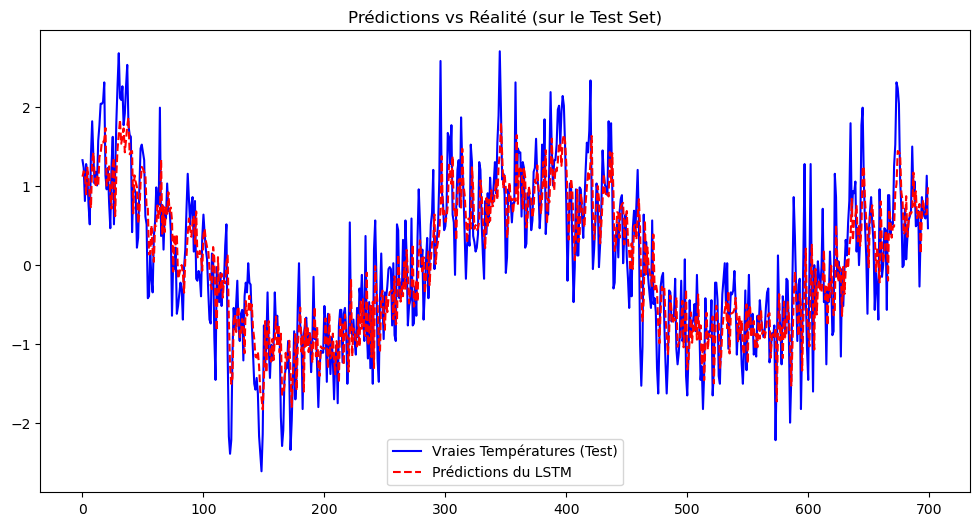

In [93]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    predictions = model(X_test_tensor).numpy()

# 3. On trace le graphique
plt.figure(figsize=(12, 6))
plt.plot(y_test, label="Vraies Températures (Test)", color='blue')
plt.plot(predictions, label="Prédictions du LSTM", color='red', linestyle='--')
plt.title("Prédictions vs Réalité (sur le Test Set)")
plt.legend()
plt.show()

# SAUVEGARDE DU MODELE

In [95]:
dummy_input = torch.randn(1, 30, 1)

In [96]:
traced_model = torch.jit.trace(model, dummy_input)

traced_model.save("temp_lstm_traced.pt")

print(" Modèle sauvegardé en TorchScript !")

 Modèle sauvegardé en TorchScript !


# TEST DU MODELE

In [97]:
loaded_model = torch.jit.load("temp_lstm_traced.pt")
loaded_model.eval()

test_window = X_test_tensor[0:1]  

with torch.no_grad():
    pred_original = model(test_window)

with torch.no_grad():
    pred_traced = loaded_model(test_window)

print("Prédiction PyTorch classique :", pred_original.item())
print("Prédiction TorchScript       :", pred_traced.item())

Prédiction PyTorch classique : 1.1197819709777832
Prédiction TorchScript       : 1.1197819709777832
